# **1- Veriyi hazırla ve tabanı kur. Tiny Shakespeare'i oku, karakter tokenizer'ını yaz (encode, decode), veriyi %90 train, %10 val diye ayır. Rastgele parçalardan batch çeken get_batch fonksiyonunu yaz. Hafta 2'deki bigram modelini nn.Module olarak kur, eğit, val loss'u kaydet. Bu senin karşılaştırma tabanın. (7:52 - 38:00**

In [ ]:
# We always start with a dataset to train on. Let's download the tiny shakespeare dataset
!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

--2026-10-02 12:30:23--  https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.109.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt’

input.txt           100%[===================>]   1.06M  --.-KB/s    in 0.01s   

2026-10-02 12:30:23 (93.1 MB/s) - ‘input.txt’ saved [1115394/1115394]



In [ ]:
# read it in to inspect it
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

In [ ]:
print("length of dataset in characters: ", len(text))

length of dataset in characters:  1115394


In [ ]:
# let's look at the first 1000 characters
print(text[:1000])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in thirst for revenge.



In [ ]:
# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(''.join(chars))
print(vocab_size)


 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
65


In [ ]:
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s] # encoder : bizim stringleri integer'a dönüştüren fonksiyonumuz. = stoi
decode = lambda l: ''.join([itos[i] for i in l]) # decoder: integerları stringe dönüştüren fonksiyonumuz. = itos

print(encode("hii there"))
print(decode(encode("hii there")))

[46, 47, 47, 1, 58, 46, 43, 56, 43]
hii there


In [ ]:
# let's now encode the entire text dataset and store it into a torch.Tensor
import torch # we use PyTorch: https://pytorch.org
data = torch.tensor(encode(text), dtype=torch.long)
print(data.shape, data.dtype)
print(data[:1000]) # Burada tüm text datasetini encode edip ilk 1000 değerini bastırıyoruz.

torch.Size([1115394]) torch.int64
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  0,  0, 18, 47, 56, 57, 58,  1, 15, 47,
        58, 47, 64, 43, 52, 10,  0, 37, 53, 59,  1, 39, 56, 43,  1, 39, 50, 50,
         1, 56, 43, 57, 53, 50, 60, 43, 42,  1, 56, 39, 58, 46, 43, 56,  1, 58,
        53,  1, 42, 47, 43,  1, 58, 46, 39, 52,  1, 58, 53,  1, 44, 39, 51, 47,
        57, 46, 12,  0,  0, 13, 50, 50, 10,  0, 30, 43, 57, 53, 50, 60, 43, 42,
         8,  1, 56, 43, 57, 53, 50, 60, 43, 42,  8,  0,  0, 18, 47, 56, 57, 58,
         1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 18, 47, 56, 57, 58,  6,  1, 63,
        53, 59,  1, 49, 52, 53, 61,  1, 15, 39, 47, 59, 57,  1, 25, 39, 56, 41,
      

In [ ]:
# Datayı %90 train %10 val diye böldük.
n = int(0.9*len(data)) # first 90% will be train, rest val
train_data = data[:n]
val_data = data[n:]

In [ ]:
block_size = 8
train_data[:block_size+1]

tensor([18, 47, 56, 57, 58,  1, 15, 47, 58])

In [ ]:
# Burada contexti 1'den başlatıp block size'a kadar yükseltiyoruz. Burada tüm metni tekte transformer'a veremeyiz çünkü bunun hesaplama maliyeti çok yüksek olurdu.
# 1'den 8'e kadar her bağlam uzunluğunda eğitmenin sebebi sadece verimlilik değil. Model böylece tek karakterlik bağlamdan tahmin yapmaya da alışıyor.
# Metin üretimi tek karakterle başlatılabiliyor. Bağlam 8'i geçince eski karakterler kesilip atılıyor, çünkü model hiçbir zaman block_size'tan fazlasını görmüyor
x = train_data[:block_size]
y = train_data[1:block_size+1]
for t in range(block_size):
    context = x[:t+1]
    target = y[t]
    print(f"when input is {context} the target: {target}")

when input is tensor([18]) the target: 47
when input is tensor([18, 47]) the target: 56
when input is tensor([18, 47, 56]) the target: 57
when input is tensor([18, 47, 56, 57]) the target: 58
when input is tensor([18, 47, 56, 57, 58]) the target: 1
when input is tensor([18, 47, 56, 57, 58,  1]) the target: 15
when input is tensor([18, 47, 56, 57, 58,  1, 15]) the target: 47
when input is tensor([18, 47, 56, 57, 58,  1, 15, 47]) the target: 58


In [ ]:
# burada zaman boyutunun yanına ek bir boyut ekliyoruz : batch. Birden fazla parça tek bir tensörde üst üste konuyor ve GPU'ya paralel işletiliyor.
#
torch.manual_seed(1337)
batch_size = 4 # how many independent sequences will we process in parallel?
block_size = 8 # what is the maximum context length for predictions?

def get_batch(split): #   burada
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,)) # burada torch.randint ile rastgele başlangıç noktaları seçiyoruz.
    x = torch.stack([data[i:i+block_size] for i in ix]) # o noktalardan itibaren block size kadar karakter ve bir kaydırılmış (y) alıp torch.stack ile 4x8 lik tensör oluştuluyor.
    y = torch.stack([data[i+1:i+block_size+1] for i in ix]) # burada birbirinden bağımsız toplam 32 örnek var.
    return x, y

xb, yb = get_batch('train')
print('inputs:')
print(xb.shape)
print(xb)
print('targets:')
print(yb.shape)
print(yb)

print('----')

for b in range(batch_size): # batch dimension
    for t in range(block_size): # time dimension
        context = xb[b, :t+1]
        target = yb[b,t]
        print(f"when input is {context.tolist()} the target: {target}")

inputs:
torch.Size([4, 8])
tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54]])
targets:
torch.Size([4, 8])
tensor([[43, 58,  5, 57,  1, 46, 43, 39],
        [53, 56,  1, 58, 46, 39, 58,  1],
        [58,  1, 58, 46, 39, 58,  1, 46],
        [17, 27, 10,  0, 21,  1, 54, 39]])
----
when input is [24] the target: 43
when input is [24, 43] the target: 58
when input is [24, 43, 58] the target: 5
when input is [24, 43, 58, 5] the target: 57
when input is [24, 43, 58, 5, 57] the target: 1
when input is [24, 43, 58, 5, 57, 1] the target: 46
when input is [24, 43, 58, 5, 57, 1, 46] the target: 43
when input is [24, 43, 58, 5, 57, 1, 46, 43] the target: 39
when input is [44] the target: 53
when input is [44, 53] the target: 56
when input is [44, 53, 56] the target: 1
when input is [44, 53, 56, 1] the target: 58
when input is [44, 53, 56, 1, 58] the target: 46
when input is [44, 53

In [ ]:
print(xb) # our input to the transformer

tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54]])


Şimdi aşağıda bigram modelimizi yazmaya başlıyoruz.

Aşağıdaki generate fonksiyonunda : B×T boyutundaki bağlamı her adımda bir token uzatıyor: B×(T+1), B×(T+2)… Bu max_new_tokens kadar sürüyor. Her adım şöyle işliyor: modeli çalıştır → son zaman adımının logit'lerini al → softmax → torch.multinomial ile bir örnek çek → sonucu torch.cat ile bağlamın sonuna ekle. Üretim sırasında hedef olmadığı için targets=None opsiyonel yapılıyor; o durumda loss hesaplanmıyor. Üretim 0 ile başlatılıyor, yani yeni satır karakteriyle. Model eğitilmediği için çıktı anlamsız. Bir not düşüyor: Bigram modeli için tüm geçmişi modele vermek gereksiz, sadece son karakter kullanılıyor. Fonksiyonu yine de böyle genel yazıyor, çünkü ileride Transformer geçmişi gerçekten kullanacak.

In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F
torch.manual_seed(1337)

class BigramLanguageModel(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size) # bizim embedding vectörümüz 65x65. Girdideki her sayı tablodaki kendi satırını çekiyor.

    def forward(self, idx, targets=None):

        # idx and targets are both (B,T) tensor of integers
        logits = self.token_embedding_table(idx) # (B,T,C)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T) # pytorch bizden B,C,T formatında istiyor ama bizim B,T,C. O yüzden B*T yi target olarak veriyoruz. Hedefler de B*T boyutuna iniyor sabitleniyor.
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            # get the predictions
            logits, loss = self(idx)
            # focus only on the last time step
            logits = logits[:, -1, :] # becomes (B, C)
            # apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1) # (B, C)
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
        return idx

m = BigramLanguageModel(vocab_size)
logits, loss = m(xb, yb)
print(logits.shape)
print(loss)

print(decode(m.generate(idx = torch.zeros((1, 1), dtype=torch.long), max_new_tokens=100)[0].tolist()))


torch.Size([32, 65])
tensor(4.8786, grad_fn=<NllLossBackward0>)

SKIcLT;AcELMoTbvZv C?nq-QE33:CJqkOKH-q;:la!oiywkHjgChzbQ?u!3bLIgwevmyFJGUGp
wnYWmnxKWWev-tDqXErVKLgJ


Yukarıdaki çıktı çok saçma çıktı çünkü bu hem eğitilmiş bir model değil hem de bir bigram modeli. Bigram olmasından dolayı model bir harf üretmek için sadece bir önceki  harfe bakıyor. Bu çıktının uzun olmasının sebebi ise biz bu yapıyı, değiştirip, önceki tüm harflere bakan yapıyı kurup transformer'a taşıyacağız.

şimdi bigram modelimizi eğitelim.

In [ ]:
# create a PyTorch optimizer
optimizer = torch.optim.AdamW(m.parameters(), lr=1e-3)

In [ ]:
batch_size = 32
for steps in range(10000): # increase number of steps for good results...

    # sample a batch of data
    xb, yb = get_batch('train')

    # evaluate the loss
    logits, loss = m(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

print(loss.item())


2.382369041442871


loss'umuz 2.38'e kadar indi. şimdi çıktı alalım.

In [ ]:
# şimdi tekrar çıktı alalım. Bu sefer dataya daha benzer bir çıktı bekliyoruz.
print(decode(m.generate(idx = torch.zeros((1, 1), dtype=torch.long), max_new_tokens=300)[0].tolist()))


lso br. ave aviasurf my, yxMPZI ivee iuedrd whar ksth y h bora s be hese, woweee; the! KI 'de, ulseecherd d o blllando;LUCEO, oraingofof win!
RIfans picspeserer hee tha,
TOFonk? me ain ckntoty ded. bo'llll st ta d:
ELIS me hurf lal y, ma dus pe athouo
BEY:! Indy; by s afreanoo adicererupa anse tecor


Çıktı hala shakespeare'e benzemiyor hala ama artık metin yapısını anlamaya başlamış model

# **2- Geçmişin ortalamasını üç yoldan al: for döngüsüyle, lower triangular matrisle (torch.tril) çarparak, softmax'la. Üçünün aynı sonucu verdiğini torch.allclose ile göster. Matris çarpımının neden ağırlıklı ortalama olduğunu kendi cümlelerinle yaz. (42:13 - 58:26)**

**Self Attention'ın içindeki matematiksel hile**

Aşağıdaki küçük örnekle 8 token'ın birbiri ile iletişime geçmesini sağlamaya çalışıyoruz. Burada mesela 5. token sadece 1. 2. 3. ve 4. tokenlarla iletişime geçmeli. Kendinden sonraki tokenları görmemeli. En basit iletişim yolu kendinden önceki tüm tokenların ortalamasını almak. Bu çok kayıplı bir yöntem çünkü tokenların sırası kayboluyor, ama şimdilik sorun değil çünkü bu bilgiyi ileride geri getireceğiz.

In [ ]:
#consider the following toy example:

torch.manual_seed(1337)
B,T,C = 4,8,2 # batch, time, channel
x = torch.randn(B,T,C)
x.shape

torch.Size([4, 8, 2])

In [ ]:
# version 1 : for döngüsü
# Biz burada bu tokenların iletişime geçmesini şu şekilde yapmak istiyoruz : Kendinden önceki tokenların ortalamasını alarak.
xbow = torch.zeros((B,T,C))
for b in range(B):
    for t in range(T):
        xprev = x[b,:t+1] # (t,C)
        xbow[b,t] = torch.mean(xprev, 0)

# her batch elemanı ve her t için x[b, :t+1].mean(0) hesaplanıyor. Doğru çalışıyor ama verimsiz.

In [ ]:
# toy example illustrating how matrix multiplication can be used for a "weighted aggregation"
torch.manual_seed(42)
a = torch.ones(3, 3)
b = torch.randint(0,10,(3,2)).float()
c = a @ b
print('a=')
print(a)
print('--')
print('b=')
print(b)
print('--')
print('c=')
print(c)

a=
tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])
--
b=
tensor([[2., 7.],
        [6., 4.],
        [6., 5.]])
--
c=
tensor([[14., 16.],
        [14., 16.],
        [14., 16.]])


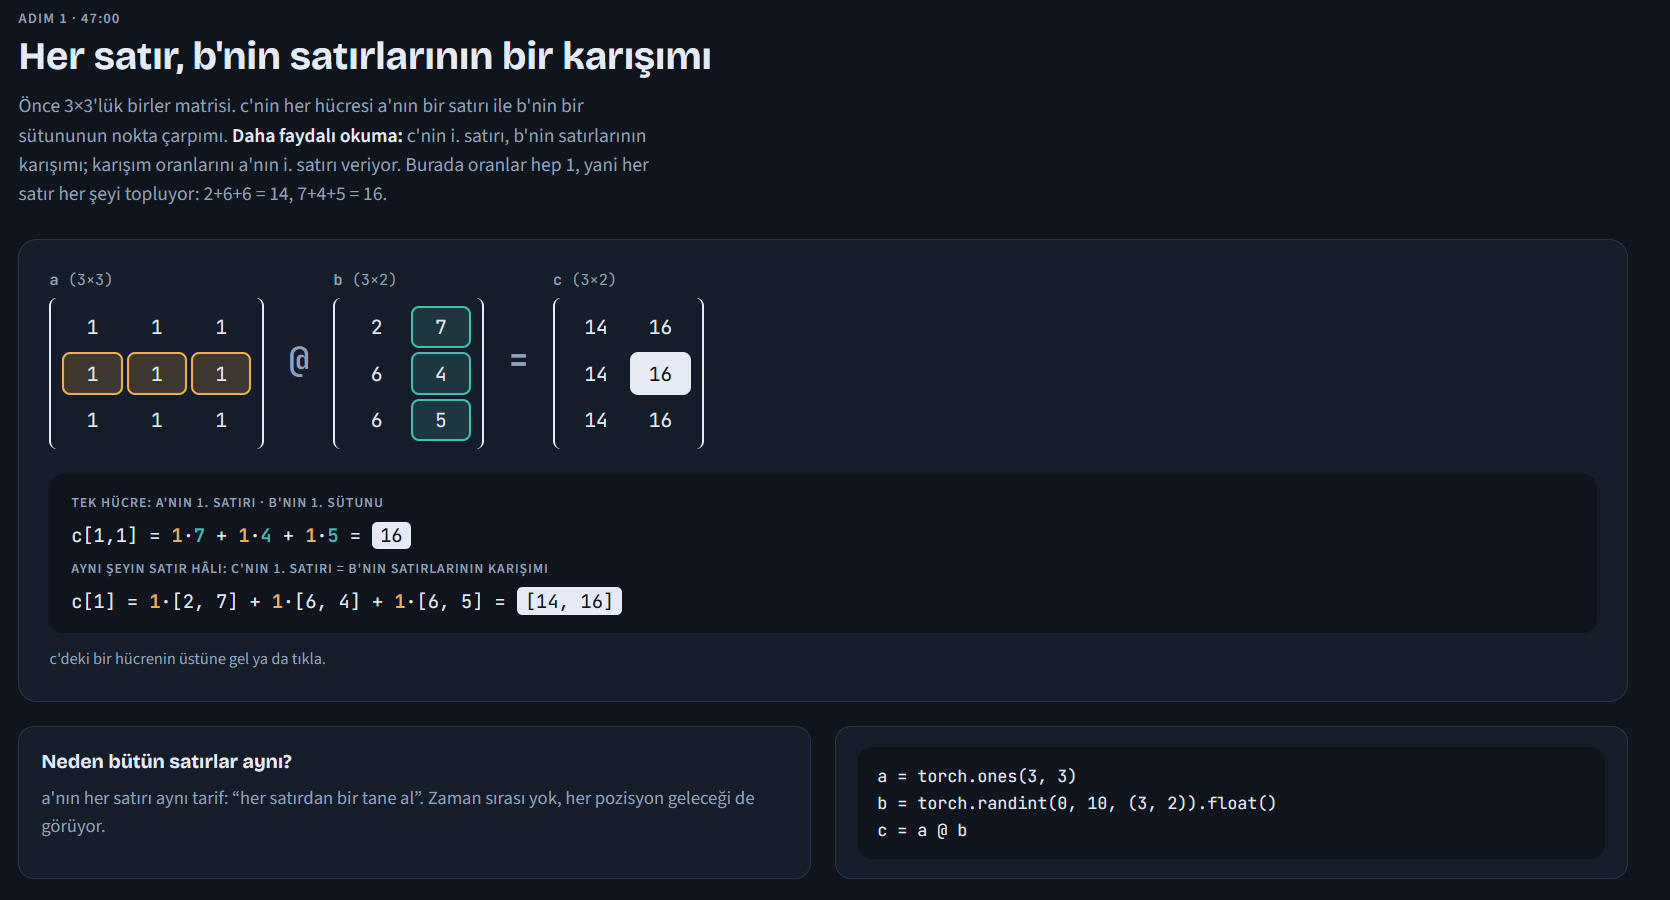

In [ ]:
# Lower triangle versiyonu. Neden bunun kullanıldığını aşağıdaki görsel açıklıyor.
torch.manual_seed(42)
a = torch.tril(torch.ones(3, 3)) # lower triangle şuanki tokenın, gelecekteki tokenlarla iletişimini engelliyor
a = a / torch.sum(a, 1, keepdim=True) # satır bazlı toplam ile normalize ediyoruz toplam değerlerini.
b = torch.randint(0,10,(3,2)).float()
c = a @ b
print('a=')
print(a)
print('--')
print('b=')
print(b)
print('--')
print('c=')
print(c)

a=
tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.3333, 0.3333, 0.3333]])
--
b=
tensor([[2., 7.],
        [6., 4.],
        [6., 5.]])
--
c=
tensor([[2.0000, 7.0000],
        [4.0000, 5.5000],
        [4.6667, 5.3333]])


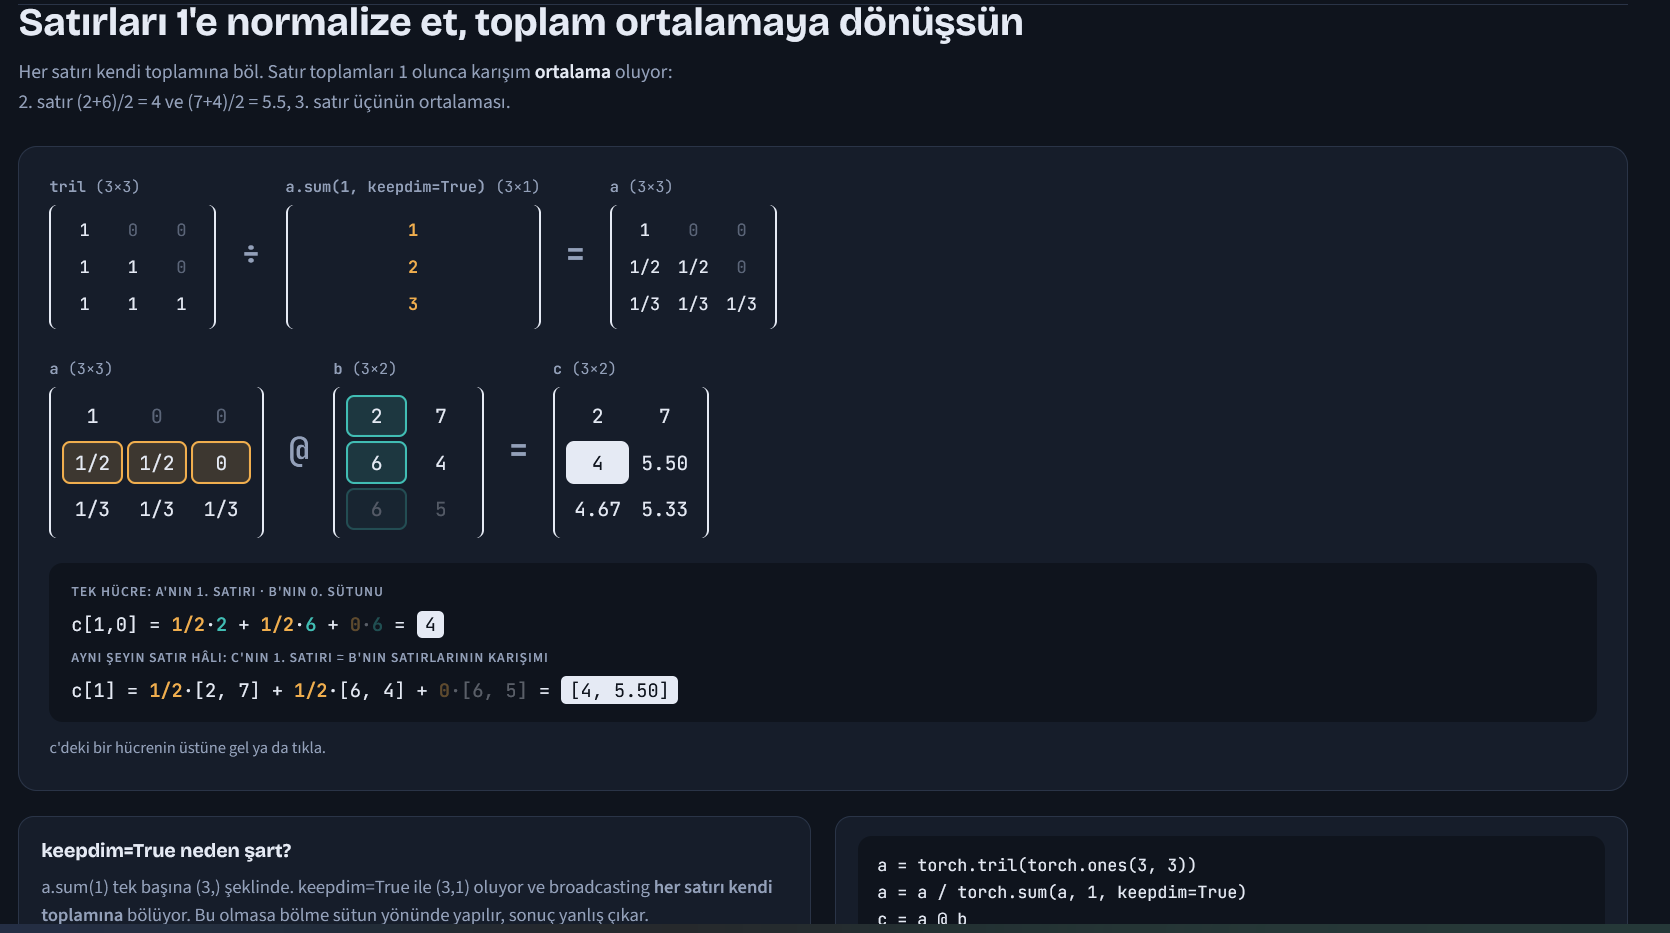

In [ ]:
# version 2: using matrix multiply for a weighted aggregation
wei = torch.tril(torch.ones(T, T))
wei = wei / wei.sum(1, keepdim=True)
xbow2 = wei @ x # (B, T, T) @ (B, T, C) ----> (B, T, C)
print(torch.allclose(xbow, xbow2))
print((xbow - xbow2).abs().max()) # false yazıyor ama fark çok çok kücük yani aslında aynı.

False
tensor(3.2363e-08)


Şekiller nasıl uyuşuyor? wei 2 boyutlu, x 3 boyutlu. PyTorch wei'nin başına sanal bir batch boyutu ekliyor: (1×8×8). Bunu 4 batch'e yayıyor ve her batch elemanı için ayrı ayrı (8×8) @ (8×2) = (8×2) çarpımını paralel yapıyor. Sonuç (4×8×2). Buna batched matmul deniyor.

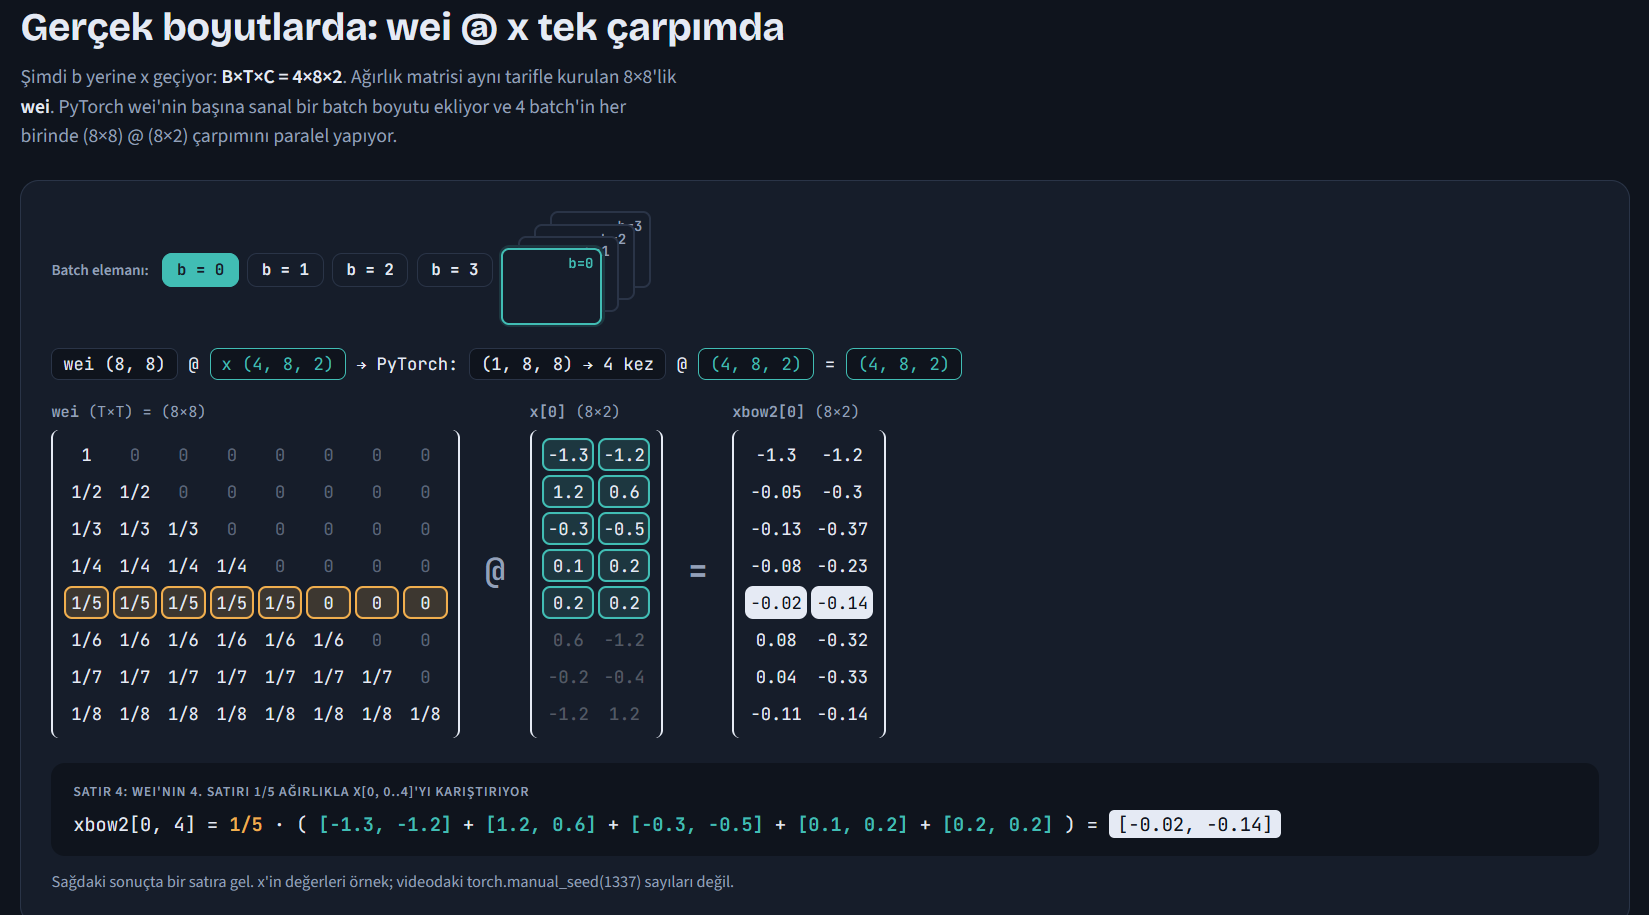

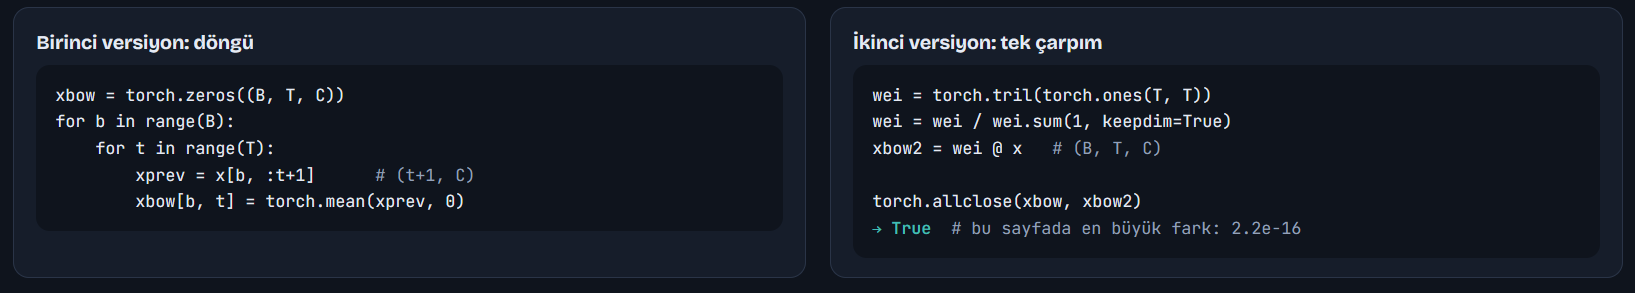

In [ ]:
# version 3: use Softmax
tril = torch.tril(torch.ones(T, T))
wei = torch.zeros((T,T)) # affinite puanları. i. token j. token ile ne kadar ilgilenmeli ?
wei = wei.masked_fill(tril == 0, float('-inf')) # burada tril matrixindeki 0 olan yerleri (gelecek bilgisini yani) -inf'e çeviriyoruz.
wei = F.softmax(wei, dim=-1) #softmax ile dağılıma çeviriyoruz.
xbow3 = wei @ x
print(torch.allclose(xbow, xbow3))
print((xbow - xbow3).abs().max()) # false yazıyor ama fark çok çok kücük yani aslında aynı.

False
tensor(3.2363e-08)


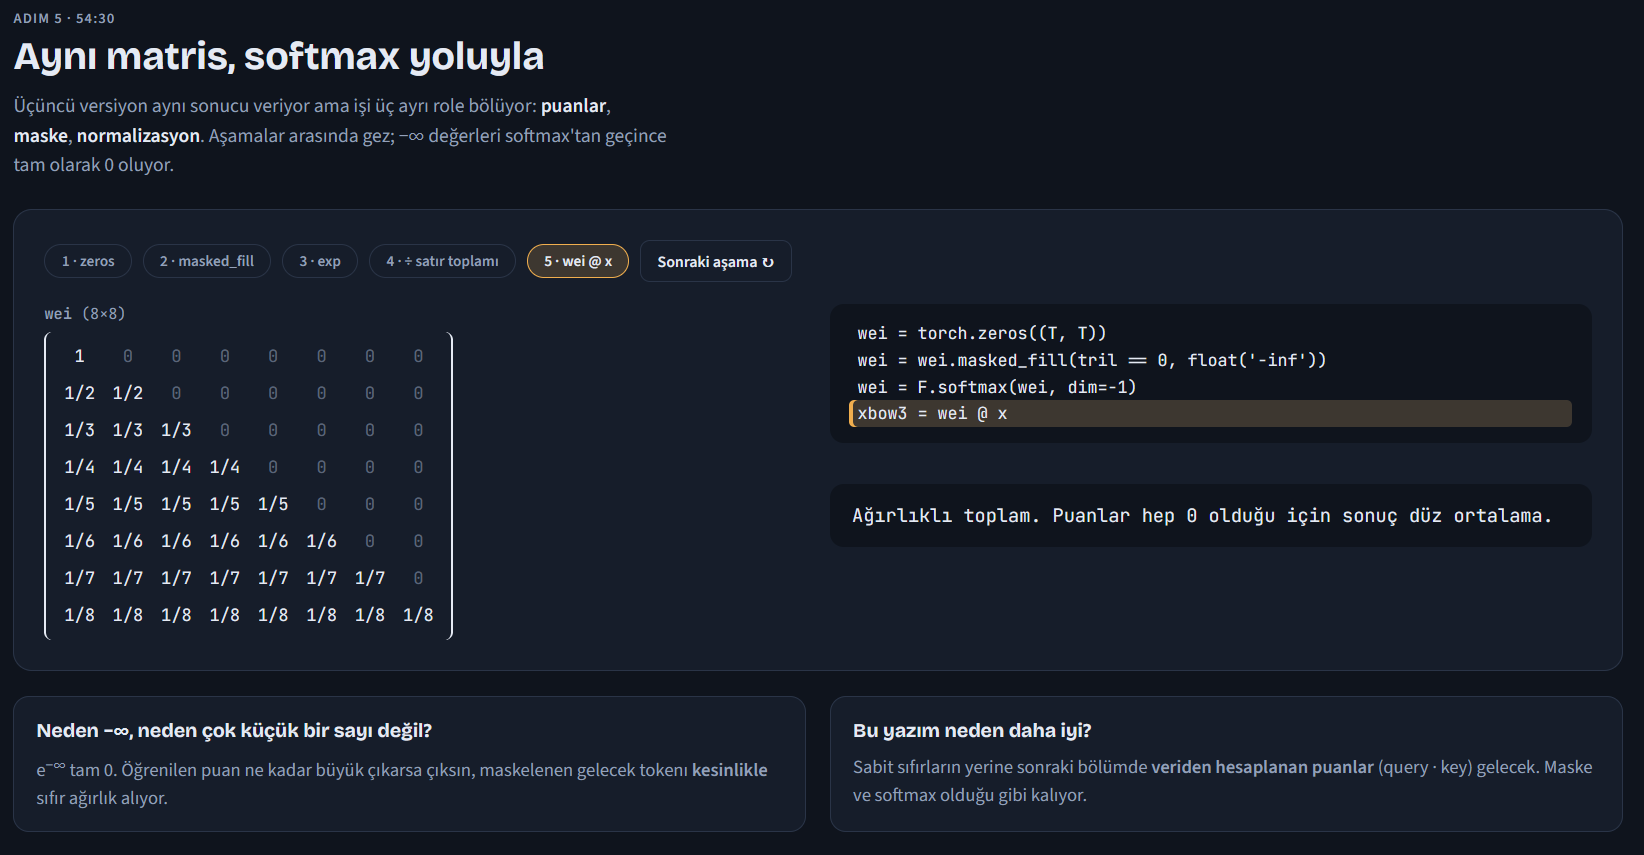

Bu softmax de aynı sonucu verdi ama neden bu kadar dolambaçlı ?


Bu fonksiyonların şu an ne yaptığı kodun yorum satırlarında yazıyor. Ama transformer'a geçince ne yapacak :


'wei = torch.zeros((T,T))' : Sabit 0 yerine veriden hesaplanacak (query·key)
'wei = wei.masked_fill' : Aynen kalacak (decoder'da)
'softmax' : Aynen kalacak
'wei @ x' : Aynen kalacak (x yerine value gelecek)

Şu an bütün puanlar 0 olduğu için softmax hepsine eşit ağırlık veriyor, sonuç düz ortalama. Self-attention'da puanlar örneğin [2.1, -0.3, 0.8] gibi olacak. Softmax bunu kabaca [0.72, 0.07, 0.21]'e çevirecek ve token geçmişin her parçasından farklı oranda bilgi alacak. Örneğin bir sesli harf, kendinden önceki ünsüzlere daha çok dikkat edebilir.

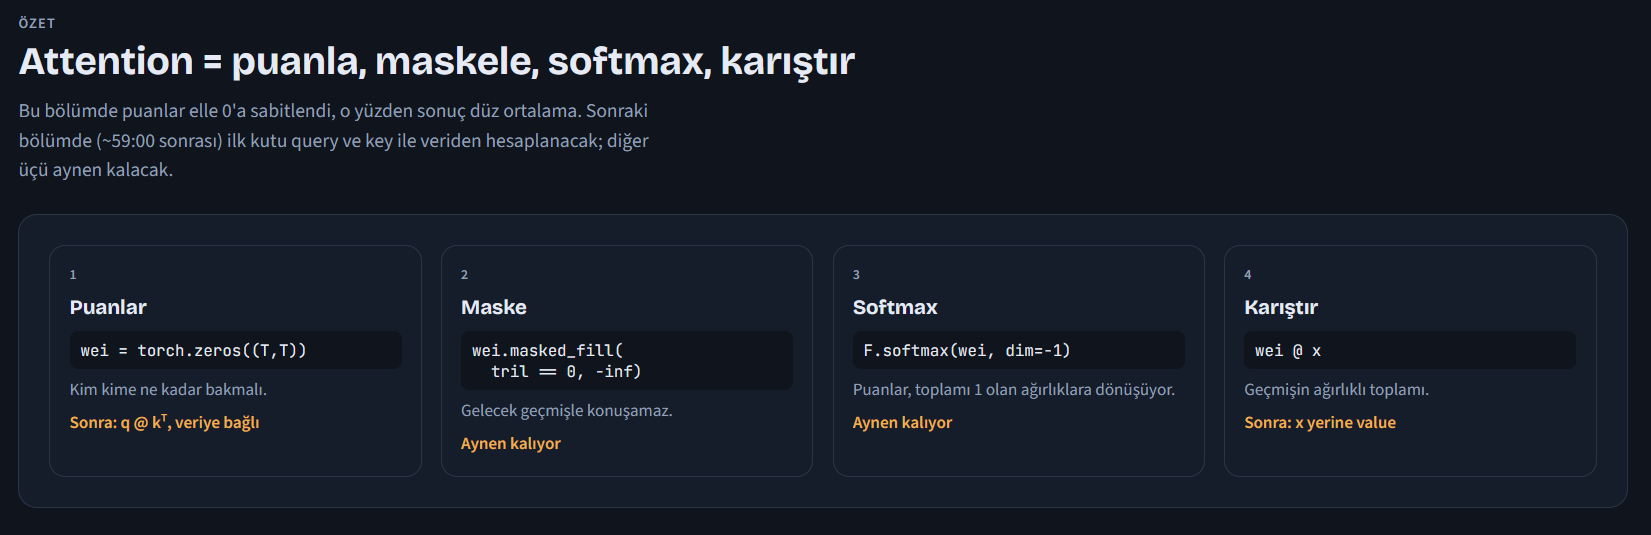

# **3- Tek bir self-attention head yaz: query, key, value ve pozisyon embedding'i. Bir örnekte ağırlık matrisini (wei) yazdır, bir satırını oku: o token hangi token'lara ne kadar bakıyor. Skorları head_size'ın kareköküne neden böldüğümüzü sayıyla göster: bölmeden ve bölerek softmax çıktısını yan yana koy. (58:26 - 1:19:11)**

Position Embedding nedir ?

position embedding implementasyonu, her token'ın kimlik vektörüne(token embedding,BxTxC) bir de konum vektörü (TxC) ekledi.

x = tok_emb + pos_emb

Broadcasting sayesinde konum vektörü batch'teki her örneğe eklendi. Fakat sadece bunu eklememiz işe yaramıyor çünkü hala bigram model kullanıyoruz, yani model sadece kendisinden yalnızca bir önceki token'a bakıyor. Attention mekanizmasını implemente ettiğimiz zaman position embedding'in önemi daha da ortaya çıkacak.

Ve şöyle bir şey daha var. Bizim yukarıdaki 3 yöntem de çalışıyordu fakat uniform dağılım sergiliyordu. Lakin bir token, kendisinden önceki her token'la eşit iletişim kurmaz. Karpathy'nin örneği de : "eğer bu token bir sesli harf ise kendisinden önceki sessiz harfleri arıyor olabilir". Yani ağırlıklar veriye bağlı olmalı. Bu problemi ise self attention ile çözeceğiz.

Attention'da:

Key = Bende ne var ?
Query = Ne arıyorum ?

İki token arasındaki yakınlık, yani affinity = bir tokenin query'si ile diğerinin key'inin dot product'ı. Bu iki vektör hizalıysa skor yüksek çıkıyor ve o token'dan daha fazla bilgi alınıyor.

In [ ]:
# version 4: self-attention!
torch.manual_seed(1337)
B,T,C = 4,8,32 # batch, time, channels
x = torch.randn(B,T,C)

# let's see a single Head perform self-attention
head_size = 16
key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
k = key(x)   # (B, T, 16) Ben kimim sorusu
q = query(x) # (B, T, 16) Ne arıyorum sorusu
wei =  q @ k.transpose(-2, -1) # (B, T, 16) @ (B, 16, T) ---> (B, T, T) matmul yapabilmek için transpose alıyoruz ama sadece son iki dimension'da çünkü B yerinde kalmalı.

tril = torch.tril(torch.ones(T, T))
#wei = torch.zeros((T,T)) wei artık q ve k'dan oluştuğu için bu satırı kaldırdık.
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)
out = wei @ x

out.shape

torch.Size([4, 8, 32])

In [ ]:
wei

tensor([[[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.1574, 0.8426, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.2088, 0.1646, 0.6266, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.5792, 0.1187, 0.1889, 0.1131, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0294, 0.1052, 0.0469, 0.0276, 0.7909, 0.0000, 0.0000, 0.0000],
         [0.0176, 0.2689, 0.0215, 0.0089, 0.6812, 0.0019, 0.0000, 0.0000],
         [0.1691, 0.4066, 0.0438, 0.0416, 0.1048, 0.2012, 0.0329, 0.0000],
         [0.0210, 0.0843, 0.0555, 0.2297, 0.0573, 0.0709, 0.2423, 0.2391]],

        [[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.1687, 0.8313, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.2477, 0.0514, 0.7008, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.4410, 0.0957, 0.3747, 0.0887, 0.0000, 0.0000, 0.0000, 0.0000],
         [0.0069, 0.0456, 0.0300, 0.7748, 0.1427, 0.0000, 0.0000, 0.0000],
         [0.0660, 0.089

In [ ]:
wei[0]

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1574, 0.8426, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2088, 0.1646, 0.6266, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5792, 0.1187, 0.1889, 0.1131, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0294, 0.1052, 0.0469, 0.0276, 0.7909, 0.0000, 0.0000, 0.0000],
        [0.0176, 0.2689, 0.0215, 0.0089, 0.6812, 0.0019, 0.0000, 0.0000],
        [0.1691, 0.4066, 0.0438, 0.0416, 0.1048, 0.2012, 0.0329, 0.0000],
        [0.0210, 0.0843, 0.0555, 0.2297, 0.0573, 0.0709, 0.2423, 0.2391]],
       grad_fn=<SelectBackward0>)

aşağıda mask olmadığında ne oluyor bakalım.

In [ ]:
# version 4: self-attention!
torch.manual_seed(1337)
B,T,C = 4,8,32 # batch, time, channels
x = torch.randn(B,T,C)

# let's see a single Head perform self-attention
head_size = 16
key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
k = key(x)   # (B, T, 16) Ben kimim sorusu
q = query(x) # (B, T, 16) Ne arıyorum sorusu
wei =  q @ k.transpose(-2, -1) # (B, T, 16) @ (B, 16, T) ---> (B, T, T) matmul yapabilmek için transpose alıyoruz ama sadece son iki dimension'da çünkü B yerinde kalmalı.

tril = torch.tril(torch.ones(T, T))
#wei = torch.zeros((T,T))
#wei = wei.masked_fill(tril == 0, float('-inf'))
#wei = F.softmax(wei, dim=-1)
out = wei @ x

out.shape
print(wei[0])

tensor([[-1.7629, -1.3011,  0.5652,  2.1616, -1.0674,  1.9632,  1.0765, -0.4530],
        [-3.3334, -1.6556,  0.1040,  3.3782, -2.1825,  1.0415, -0.0557,  0.2927],
        [-1.0226, -1.2606,  0.0762, -0.3813, -0.9843, -1.4303,  0.0749, -0.9547],
        [ 0.7836, -0.8014, -0.3368, -0.8496, -0.5602, -1.1701, -1.2927, -1.0260],
        [-1.2566,  0.0187, -0.7880, -1.3204,  2.0363,  0.8638,  0.3719,  0.9258],
        [-0.3126,  2.4152, -0.1106, -0.9931,  3.3449, -2.5229,  1.4187,  1.2196],
        [ 1.0876,  1.9652, -0.2621, -0.3158,  0.6091,  1.2616, -0.5484,  0.8048],
        [-1.8044, -0.4126, -0.8306,  0.5899, -0.7987, -0.5856,  0.6433,  0.6303]],
       grad_fn=<SelectBackward0>)


Gördüğünüz gibi 5. sıradaki token, gelecekteki tokenlardan bilgi alabiliyor. Biz bunu istemiyoruz. Şimdi Value implementasyonu yapalım.

Value ile beraber artık aggregation'ı x üzerinden değil, üçüncü bir projeksiyon olan v üzerinden yapılıyor. Artık :

x = token'ın özel bilgisi
q = Bunu arıyorum
k = Bende bu var
v = Beni ilginç bulursan sana haber vereceğim

In [ ]:
# version 4: self-attention!
torch.manual_seed(1337)
B,T,C = 4,8,32 # batch, time, channels
x = torch.randn(B,T,C)

# let's see a single Head perform self-attention
head_size = 16
key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)
k = key(x)   # (B, T, 16) Ben kimim sorusu
q = query(x) # (B, T, 16) Ne arıyorum sorusu
wei =  q @ k.transpose(-2, -1) # (B, T, 16) @ (B, 16, T) ---> (B, T, T) matmul yapabilmek için transpose alıyoruz ama sadece son iki dimension'da çünkü B yerinde kalmalı.

tril = torch.tril(torch.ones(T, T))
#wei = torch.zeros((T,T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)

v = value(x)
out = wei @ v
#out = wei @ x artık x'le değil v ile aggregation yapıyoruz.

out.shape
print(wei[0])

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1574, 0.8426, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2088, 0.1646, 0.6266, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5792, 0.1187, 0.1889, 0.1131, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0294, 0.1052, 0.0469, 0.0276, 0.7909, 0.0000, 0.0000, 0.0000],
        [0.0176, 0.2689, 0.0215, 0.0089, 0.6812, 0.0019, 0.0000, 0.0000],
        [0.1691, 0.4066, 0.0438, 0.0416, 0.1048, 0.2012, 0.0329, 0.0000],
        [0.0210, 0.0843, 0.0555, 0.2297, 0.0573, 0.0709, 0.2423, 0.2391]],
       grad_fn=<SelectBackward0>)


Notlar

1- Attention bir iletişim mekanizmasıdır. Yönlü graflardaki node'lar gibi represente edilebilir, birbirini gören ve veri bağımlı şekilde tüm nodeların ağırlıklı toplamlarıyla bilgilerin toplanması işlemidir.

2- Uzay kavramı yok. Konvolüsyonla farkı bu. Konvolüsyonda filtre uzayda kayıyor ve bilginin yerleşimi yapının içine gömülü. Attention ise havada duran bir vektör kümesi gibi: vektörler konuşuyor ama kimse nerede durduğunu bilmiyor. Konum bilgisi isteniyorsa elle eklenmesi gerekiyor. Bu yüzden position embedding var.

3- Batch elemanları birbiriyle hiç konuşmaz. Batch 4, blok 8 ise toplam 32 düğüm işleniyor. Ama bunlar 8'er düğümlük 4 ayrı havuz. Her havuz yalnızca kendi içinde konuşuyor. Batched matmul bu 4 havuzu paralel ama birbirinden bağımsız işliyor.

4- Encoder ve decoder bloğu. Aradaki fark tek satır kod, masked_fill(tril == 0, -inf):
  - Decoder: Maske var, gelecek geçmişle konuşamaz. Konuşabilseydi cevap ele verilirdi. Dil üretimi için kullanılıyor.
  - Encoder: Satır siliniyor ve herkes herkesle konuşuyor. Duygu analizi gibi işler için uygun, çünkü bütün cümle zaten
    elde ve sonunda tek bir etiket tahmin ediliyor.

5- Attention bağlantı yapısını umursamıyor: maske ne derse grafın şekli o oluyor.

6- Ölçekleme: neden 1/√d_k? (~1:16–1:19)

  "Attention Is All You Need" makalesindeki formülde eksik kalan parça: softmax(QKᵀ / √d_k) V.

  - q ve k'nın elemanları ortalama 0, varyans 1 ise q·k toplamı 16 terimden oluşuyor ve varyansı head_size, yani 16
    oluyor.
  - √16 = 4'e bölünce varyans tekrar 1'e iniyor.

  Bu neden önemli? Çünkü wei softmax'e giriyor. Softmax'e büyük değerler (çok pozitif veya çok negatif) girerse çıktı
  one-hot'a yaklaşıyor, yani bütün ağırlık en büyük değere gidiyor. Karpathy bunu canlı gösteriyor: sıfıra yakın
  değerler dağınık bir dağılım veriyor, aynı değerleri 8 ile çarpınca dağılım sivrilip maksimuma kilitleniyor.

  Sonuç olarak ölçekleme olmazsa başlangıçta her düğüm yalnızca tek bir düğümden bilgi alıyor. Öğrenme başlamadan
  ağırlıklar keskinleşmiş oluyor. Ölçekleme, başlangıçta varyansı kontrol altında tutup dağılımı dağınık bırakmak için
  var. (Önceki haftalardaki Kaiming init ve varyans korunumu ile aynı mantık.)

In [ ]:
k = torch.randn(B,T,head_size)
q = torch.randn(B,T,head_size)
wei = q @ k.transpose(-2, -1) #* head_size**-0.5

In [ ]:
k.var()

tensor(1.0104)

In [ ]:
q.var()

tensor(1.0204)

In [ ]:
wei.var()

tensor(17.6841)

In [ ]:
torch.softmax(wei, dim = -1)
print(torch.softmax(wei, dim = -1))
#print(wei)
print(torch.softmax(wei, dim = -1).max())

tensor([[[5.4453e-06, 5.6084e-06, 3.7460e-06, 9.1017e-01, 2.6486e-02,
          6.2759e-02, 5.6734e-04, 1.4176e-10],
         [2.3396e-04, 1.0733e-05, 1.4771e-03, 4.5047e-03, 1.2487e-05,
          1.1498e-04, 6.3081e-01, 3.6283e-01],
         [8.5686e-02, 3.5676e-02, 1.1219e-01, 2.2552e-02, 6.6911e-01,
          6.0837e-02, 2.7472e-03, 1.1200e-02],
         [3.4797e-03, 4.6579e-01, 6.8331e-04, 4.9555e-01, 6.0404e-03,
          2.5760e-02, 2.6961e-03, 7.8355e-07],
         [2.6778e-01, 6.1690e-03, 5.6667e-01, 6.0907e-09, 1.6929e-06,
          1.4560e-04, 3.7728e-05, 1.5919e-01],
         [1.1265e-03, 5.6343e-04, 8.3734e-04, 4.8625e-02, 2.4531e-04,
          3.2366e-04, 6.1598e-06, 9.4827e-01],
         [2.5556e-05, 4.4033e-01, 1.4261e-02, 5.4970e-02, 1.9389e-01,
          9.0987e-02, 1.1787e-01, 8.7659e-02],
         [1.6838e-04, 2.7784e-06, 8.3195e-03, 1.2180e-02, 4.0365e-05,
          2.5665e-06, 2.3659e-05, 9.7926e-01]],

        [[9.9955e-01, 3.5084e-07, 4.3054e-06, 2.3677e-04, 4.93

ölçekleme yaparsak wei'nin varyansı 1'e yakın olur ve bu sayede wei softmax'e girdiğinde tüm ağırlıklar başlangıçtaki büyük sayılara odaklanmaz.

In [ ]:
k = torch.randn(B,T,head_size)
q = torch.randn(B,T,head_size)
wei = q @ k.transpose(-2, -1) * head_size**-0.5

In [ ]:
k.var()

tensor(1.0632)

In [ ]:
q.var()

tensor(0.9891)

In [ ]:
wei.var()

tensor(0.9755)

In [ ]:
torch.softmax(wei, dim = -1)
print(torch.softmax(wei, dim = -1))
#print(wei)
print(torch.softmax(wei, dim = -1).max())

tensor([[[0.0581, 0.2605, 0.1887, 0.0554, 0.0496, 0.1912, 0.0306, 0.1660],
         [0.0790, 0.1723, 0.3326, 0.0098, 0.0785, 0.1288, 0.1135, 0.0856],
         [0.0148, 0.0269, 0.0223, 0.1534, 0.5984, 0.0844, 0.0622, 0.0375],
         [0.0533, 0.0634, 0.1152, 0.1203, 0.1237, 0.1167, 0.1861, 0.2211],
         [0.2302, 0.0997, 0.1965, 0.0264, 0.0328, 0.0791, 0.2955, 0.0398],
         [0.0722, 0.1056, 0.3013, 0.0306, 0.0810, 0.1397, 0.0722, 0.1974],
         [0.1445, 0.2652, 0.1471, 0.0059, 0.1761, 0.2142, 0.0152, 0.0318],
         [0.0517, 0.2577, 0.4059, 0.0055, 0.0373, 0.1514, 0.0129, 0.0775]],

        [[0.0211, 0.2596, 0.0293, 0.0068, 0.0054, 0.0386, 0.5672, 0.0721],
         [0.0084, 0.1553, 0.0153, 0.0696, 0.2542, 0.1628, 0.2373, 0.0972],
         [0.0534, 0.0987, 0.0404, 0.6565, 0.0503, 0.0661, 0.0174, 0.0173],
         [0.0938, 0.0480, 0.0147, 0.0555, 0.1560, 0.0992, 0.3902, 0.1427],
         [0.0229, 0.1303, 0.1354, 0.0652, 0.0669, 0.2656, 0.0979, 0.2158],
         [0.0342, 0.162

# **4- Head'i bigram modelinin içine koy ve eğit. Val loss'u 1. görevdeki bigram tabanıyla yan yana koy. Ne kadar düştü, neden düştü, kendi cümlelerinle yaz. Metin üretirken girdiyi neden son block_size harfe kırpmak zorunda olduğunu da yaz. (1:19:11 - 1:21:59)**

In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F

# hyperparameters
batch_size = 32 # how many independent sequences will we process in parallel?
block_size = 8 # what is the maximum context length for predictions?
max_iters = 5000
eval_interval = 100
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 32
#n_head = 4
#n_layer = 4
#dropout = 0.0
# ------------

torch.manual_seed(1337)

# wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars)
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s] # encoder: take a string, output a list of integers
decode = lambda l: ''.join([itos[i] for i in l]) # decoder: take a list of integers, output a string

# Train and test splits
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9*len(data)) # first 90% will be train, rest val
train_data = data[:n]
val_data = data[n:]

# data loading
def get_batch(split):
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    x, y = x.to(device), y.to(device)
    return x, y

@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

class Head(nn.Module):
    """ one head of self-attention """

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))



    def forward(self, x):
        B,T,C = x.shape
        k = self.key(x)   # (B,T,C)
        q = self.query(x) # (B,T,C)
        # compute attention scores ("affinities")
        wei = q @ k.transpose(-2,-1) * C**-0.5 # (B, T, C) @ (B, C, T) -> (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # (B, T, T)
        wei = F.softmax(wei, dim=-1) # (B, T, T)

        # perform the weighted aggregation of the values
        v = self.value(x) # (B,T,C)
        out = wei @ v # (B, T, T) @ (B, T, C) -> (B, T, C)
        return out
# super simple bigram model
class BigramLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        #self.ln_f = nn.LayerNorm(n_embd) # final layer norm
        self.sa_head = Head(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)


    def forward(self, idx, targets=None):
        B, T = idx.shape

        # idx and targets are both (B,T) tensor of integers
        tok_emb = self.token_embedding_table(idx) # (B,T,C)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device)) # (T,C) # LEARNED ABSOLUTE
        x = tok_emb + pos_emb # (B,T,C)
        x = self.sa_head(x)
        #x = self.ln_f(x) # (B,T,C)
        logits = self.lm_head(x) # (B,T,vocab_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            # crop idx to the last block_size tokens
            idx_cond = idx[:, -block_size:]
            # get the predictions
            logits, loss = self(idx_cond)
            # focus only on the last time step
            logits = logits[:, -1, :] # becomes (B, C)
            # apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1) # (B, C)
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
        return idx

model = BigramLanguageModel()
m = model.to(device)
# print the number of parameters in the model
print(sum(p.numel() for p in m.parameters())/1e6, 'M parameters')

# create a PyTorch optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

for iter in range(max_iters):

    # every once in a while evaluate the loss on train and val sets
    if iter % eval_interval == 0 or iter == max_iters - 1:
        losses = estimate_loss()
        print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")

    # sample a batch of data
    xb, yb = get_batch('train')

    # evaluate the loss
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

# generate from the model
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(m.generate(context, max_new_tokens=2000)[0].tolist()))

0.007553 M parameters
step 0: train loss 4.2000, val loss 4.2047
step 100: train loss 3.2338, val loss 3.2548
step 200: train loss 3.0793, val loss 3.1032
step 300: train loss 2.9432, val loss 2.9652
step 400: train loss 2.7881, val loss 2.8020
step 500: train loss 2.6945, val loss 2.7148
step 600: train loss 2.6428, val loss 2.6436
step 700: train loss 2.5974, val loss 2.6025
step 800: train loss 2.5524, val loss 2.5807
step 900: train loss 2.5432, val loss 2.5592
step 1000: train loss 2.5242, val loss 2.5353
step 1100: train loss 2.5107, val loss 2.5218
step 1200: train loss 2.4874, val loss 2.5039
step 1300: train loss 2.4858, val loss 2.5070
step 1400: train loss 2.4870, val loss 2.4802
step 1500: train loss 2.4865, val loss 2.4710
step 1600: train loss 2.4707, val loss 2.4730
step 1700: train loss 2.4656, val loss 2.4661
step 1800: train loss 2.4612, val loss 2.4715
step 1900: train loss 2.4560, val loss 2.4570
step 2000: train loss 2.4413, val loss 2.4676
step 2100: train loss 2.

# **Ek, erken bitirenler için, ikisinden biri. (a) Eğitilmiş modelde bir cümlenin attention ağırlıklarını ısı haritası olarak çiz. Hangi harf hangisine bakıyor, ne gördüğünü yaz. (b) tril maskesini kaldırıp modeli yeniden eğit. Val loss ne oldu, ürettiği metin ne oldu? Sonucu gelecekteki harfleri görmekle açıkla. B SEÇENEĞİNİ SEÇTİM.**

In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F

# hyperparameters
batch_size = 32 # how many independent sequences will we process in parallel?
block_size = 8 # what is the maximum context length for predictions?
max_iters = 5000
eval_interval = 100
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 32
causal = False  # True: tril maskesi açık (decoder), False: maske yok, gelecek görünür
#n_head = 4
#n_layer = 4
#dropout = 0.0
# ------------

torch.manual_seed(1337)

# wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars)
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s] # encoder: take a string, output a list of integers
decode = lambda l: ''.join([itos[i] for i in l]) # decoder: take a list of integers, output a string

# Train and test splits
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9*len(data)) # first 90% will be train, rest val
train_data = data[:n]
val_data = data[n:]

# data loading
def get_batch(split):
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    x, y = x.to(device), y.to(device)
    return x, y

@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

class Head(nn.Module):
    """ one head of self-attention """

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))



    def forward(self, x):
        B,T,C = x.shape
        k = self.key(x)   # (B,T,C)
        q = self.query(x) # (B,T,C)
        # compute attention scores ("affinities")
        wei = q @ k.transpose(-2,-1) * C**-0.5 # (B, T, C) @ (B, C, T) -> (B, T, T)
        if causal:
              wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # (B, T, T)
        wei = F.softmax(wei, dim=-1) # (B, T, T)

        # perform the weighted aggregation of the values
        v = self.value(x) # (B,T,C)
        out = wei @ v # (B, T, T) @ (B, T, C) -> (B, T, C)
        return out
# super simple bigram model
class BigramLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        #self.ln_f = nn.LayerNorm(n_embd) # final layer norm
        self.sa_head = Head(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)


    def forward(self, idx, targets=None):
        B, T = idx.shape

        # idx and targets are both (B,T) tensor of integers
        tok_emb = self.token_embedding_table(idx) # (B,T,C)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device)) # (T,C) # LEARNED ABSOLUTE
        x = tok_emb + pos_emb # (B,T,C)
        x = self.sa_head(x)
        #x = self.ln_f(x) # (B,T,C)
        logits = self.lm_head(x) # (B,T,vocab_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            # crop idx to the last block_size tokens
            idx_cond = idx[:, -block_size:]
            # get the predictions
            logits, loss = self(idx_cond)
            # focus only on the last time step
            logits = logits[:, -1, :] # becomes (B, C)
            # apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1) # (B, C)
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
        return idx

model = BigramLanguageModel()
m = model.to(device)
# print the number of parameters in the model
print(sum(p.numel() for p in m.parameters())/1e6, 'M parameters')

# create a PyTorch optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

for iter in range(max_iters):

    # every once in a while evaluate the loss on train and val sets
    if iter % eval_interval == 0 or iter == max_iters - 1:
        losses = estimate_loss()
        print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")

    # sample a batch of data
    xb, yb = get_batch('train')

    # evaluate the loss
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

# generate from the model
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(m.generate(context, max_new_tokens=2000)[0].tolist()))

0.007553 M parameters
step 0: train loss 4.2000, val loss 4.2027
step 100: train loss 2.7907, val loss 2.8202
step 200: train loss 1.0504, val loss 1.0894
step 300: train loss 0.6486, val loss 0.6724
step 400: train loss 0.5406, val loss 0.5487
step 500: train loss 0.5045, val loss 0.5055
step 600: train loss 0.4839, val loss 0.4907
step 700: train loss 0.4703, val loss 0.4668
step 800: train loss 0.4580, val loss 0.4599
step 900: train loss 0.4555, val loss 0.4500
step 1000: train loss 0.4493, val loss 0.4460
step 1100: train loss 0.4414, val loss 0.4436
step 1200: train loss 0.4420, val loss 0.4412
step 1300: train loss 0.4373, val loss 0.4382
step 1400: train loss 0.4352, val loss 0.4351
step 1500: train loss 0.4312, val loss 0.4320
step 1600: train loss 0.4316, val loss 0.4316
step 1700: train loss 0.4287, val loss 0.4314
step 1800: train loss 0.4293, val loss 0.4253
step 1900: train loss 0.4247, val loss 0.4237
step 2000: train loss 0.4197, val loss 0.4241
step 2100: train loss 0.

### Ek görev (b): tril maskesi kaldırıldığında

  **Sonuç:** Maskeli modelde val loss ~2.4 civarındaydı. Maske kaldırılınca val loss **~0.40**'a düştü. Ancak üretilen
  metin anlamsız: `SSSS...`, `eeee...`, `aaaa...`, `yyyy...` gibi uzun tek-harf tekrarlarından oluşuyor.

  **Açıklama:** Hedef dizi `y`, girdi `x`'in bir konum kaydırılmış hâli. Yani `t` konumunun doğru cevabı `x[t+1]`. Maske
  kaldırılınca her konum gelecekteki harfleri de görebiliyor. Bu yüzden ilk 7 konum cevabı doğrudan attention ile
  sağdaki komşusundan kopyalayıp loss'u neredeyse sıfıra indiriyor. Model dili öğrenmiyor, "sağımdaki harfi kopyala"
  kuralını öğreniyor. Bu kural train ve val'de aynı işe yaradığı için iki loss da birlikte düşüyor.

  Loss'un sıfıra inmemesinin sebebi bloğun 8. konumu: o konumun sağında harf yok, hile yapamıyor ve normal tahmin ediyor
  (~2.5-3 loss). Ortalama yaklaşık (7·0 + 3) / 8 ≈ 0.4, gözlenen değerle uyumlu.

  Üretim sırasında ise model her zaman en sağdaki konumu kullanıyor ve onun sağında gelecek yok. Eğitimde güvendiği
  bilgi ortada olmadığı için attention mevcut harflere, pratikte son harfin kendisine yöneliyor ve onu kopyalıyor. Bu
  yüzden aynı harf tekrar tekrar üretiliyor. Örneklemedeki rastlantı başka bir harf seçtiğinde model o harfin döngüsüne
  geçiyor.

  **Ders:** Düşük loss iyi bir model anlamına gelmiyor. Eğitimde mevcut olan ama kullanım (üretim) sırasında olmayan bir
  bilgiye erişen model, sahte biçimde iyi görünür. Buna **veri sızıntısı** denir. Dil üretimi yapan bir modelde tril
  maskesi (decoder bloğu) bu yüzden zorunlu